# 01 · Normal bivariante con correlación baja (E1)

En este cuaderno comparamos, sobre muestras de una distribución normal bivariante, el orden que induce la
**longitud de ruta media** $\bar h_t(\mathbf{x})$ de un bosque de aislamiento con el que induce la
**profundidad de Tukey** muestral $HD(\mathbf{x}, P_n)$. Consideramos dos métodos:

- **Isolation Forest** (*iForest*; Liu, Ting y Zhou, 2012), con cortes paralelos a los ejes (`src/isolation_forest.py`);
- **Extended Isolation Forest** (EIF; Hariri, Carrasco Kind y Brunner, 2021), con cortes por hiperplanos de orientación
  aleatoria (`src/eif.py`).

Una longitud de ruta media grande indica que la observación es difícil de aislar, es decir, central; por eso
$\bar h_t$ está orientada en el mismo sentido que la profundidad. Todos los cálculos usan la configuración estándar
de la memoria: $t = 100$ árboles, submuestras de tamaño $\psi = 256$ y límite de altura $h_{lim} = \psi - 1$.

El cuaderno tiene dos partes. Primero se estudia **una réplica**, para ver cómo funcionan los métodos; es la primera
réplica de la simulación (`experiments/E1.py`), de modo que sus medidas coinciden con la fila $r = 0$ de
`results/E1.csv`. Después se resumen **las 100 réplicas**.

In [1]:
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../src")
from isolation_forest import iforest, itree, longitudes, c
from eif import eif, eif_arbol, longitudes_eif
from escenarios import normal
from profundidad import hd_muestral
from metricas import metricas_par
import visualizacion as V

PSI, T, HLIM = 256, 100, 255
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)


def bosques(X, semilla, t=T):
    # Longitudes de ruta (matriz n x t) de iForest y del EIF, con la semilla de la réplica
    random.seed(semilla)
    H_if = longitudes(X, iforest(X, t=t, psi=PSI), HLIM)
    random.seed(semilla)
    H_eif = longitudes_eif(X, eif(X, t=t, psi=PSI), HLIM)
    return {"iForest": H_if, "EIF": H_eif}


def medidas(h, hd, hd_P):
    # Medidas de la memoria frente a HD(x, P_n) y el techo (log HD_P, como en src/experimento.py)
    filas = {metodo: metricas_par(h[metodo], hd) for metodo in h}
    filas["Techo (HD poblacional)"] = metricas_par(np.log(hd_P), hd)
    return pd.DataFrame(filas).T.rename(columns=V.MEDIDAS)

## Una réplica

Generamos $n = 500$ observaciones de $N_2(\boldsymbol{\mu}, \Sigma)$ con
$$
\boldsymbol{\mu} = \begin{pmatrix} 1 \\ -0.5 \end{pmatrix}, \qquad
\Sigma = \begin{pmatrix} 1.5 & 0.3 \\ 0.3 & 1 \end{pmatrix},
$$
es decir, varianzas $1.5$ y $1$ y correlación $0.3/\sqrt{1.5} \approx 0.245$. La nube es ligeramente alargada e
inclinada. La semilla es la de la primera réplica de E1, $1000$.

Marcamos dos observaciones de referencia: $\mathbf{x}_{\mathrm{in}}$, la más próxima al centro, y
$\mathbf{x}_{\mathrm{out}}$, la más alejada, según la distancia de Mahalanobis con los parámetros verdaderos.

In [2]:
esc = normal("E1", 500, [1.0, -0.5], [[1.5, 0.3], [0.3, 1.0]])
semilla = 1000

In [3]:
X, _ = esc.muestrear(np.random.default_rng(semilla))
dM = esc.d_M(X)
i_in, i_out = int(np.argmin(dM)), int(np.argmax(dM))
print(f"x_in = {X[i_in].round(3)},  d_M = {dM[i_in]:.3f}")
print(f"x_out = {X[i_out].round(3)},  d_M = {dM[i_out]:.3f}")

x_in = [ 1.008 -0.449],  d_M = 0.051
x_out = [ 1.23 -4.16],  d_M = 3.827


Representamos la muestra junto con las elipses que contienen el $50\,\%$, el $90\,\%$ y el $99\,\%$ de la
probabilidad. Como $d_M(\mathbf{X})^2 \sim \chi^2_2$, cada elipse es el conjunto
$\{\mathbf{x} : d_M(\mathbf{x})^2 = \chi^2_{2,\alpha}\}$.

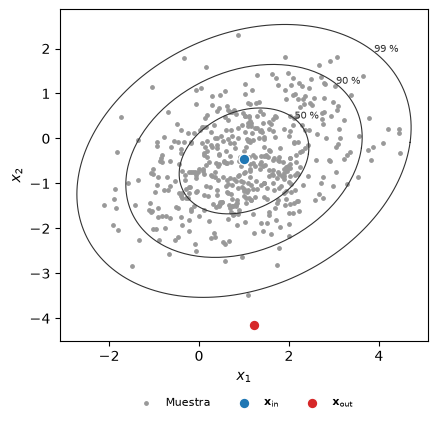

In [4]:
fig = V.dibujar_muestra(X, esc.mu, esc.Sigma, i_in, i_out)
V.guardar(fig, "E1_muestra")
plt.show()

### Cómo aísla un árbol

Construimos un único árbol de cada método sobre una submuestra de tamaño $\psi = 256$ formada por
$\mathbf{x}_{\mathrm{in}}$, $\mathbf{x}_{\mathrm{out}}$ y 254 observaciones más elegidas al azar. Recorriendo el
árbol con un punto, cada nodo interno que atraviesa corta la región en la que se encuentra, hasta que el punto queda
solo en la suya. Como los árboles se construyen completos y las observaciones son distintas, el número de cortes
coincide con la longitud de ruta $h(\mathbf{x})$. En **iForest** cada corte es una recta paralela a uno de los ejes y
las regiones son rectángulos; en el **EIF** cada corte es una recta de orientación aleatoria y las regiones son
polígonos convexos.

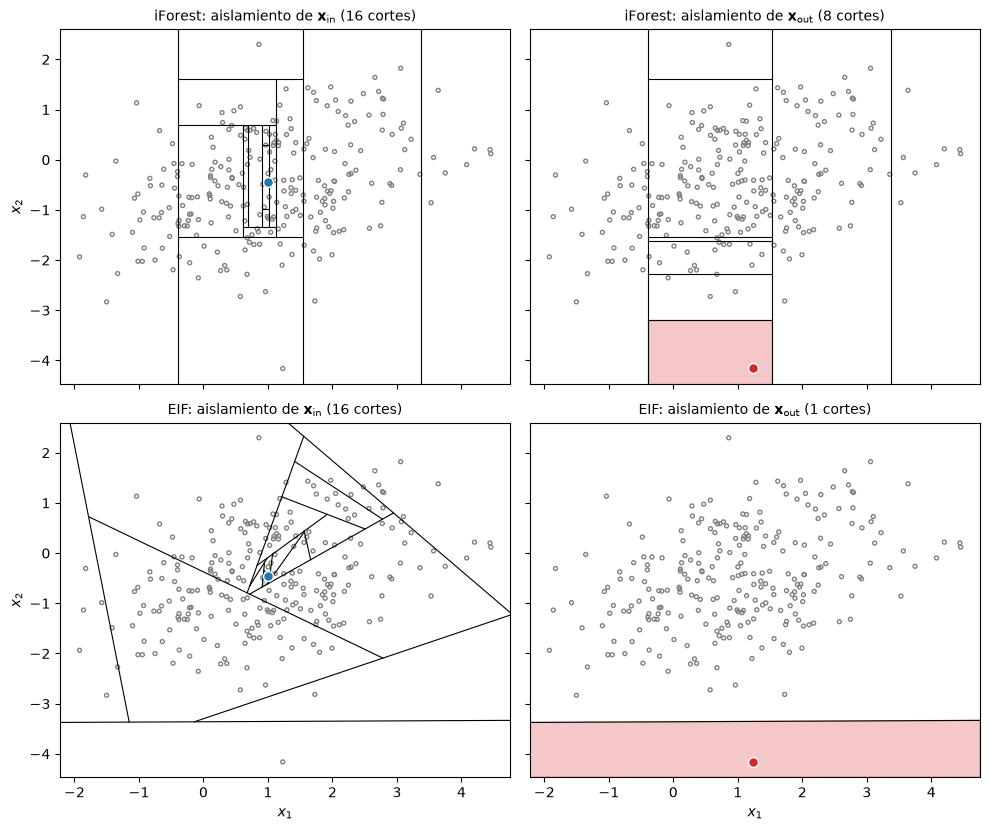

In [5]:
random.seed(semilla + 1)
resto = [j for j in range(len(X)) if j not in (i_in, i_out)]
sub = X[random.sample(resto, PSI - 2) + [i_in, i_out]]
random.seed(semilla + 1)
arboles = {"iForest": itree(sub), "EIF": eif_arbol(sub, nivel=1)}
fig = V.dibujar_aislamiento(sub, arboles, X[i_in], X[i_out])
V.guardar(fig, "E1_aislamiento")
plt.show()

Con los dos métodos, $\mathbf{x}_{\mathrm{out}}$ queda aislado tras muy pocos cortes y $\mathbf{x}_{\mathrm{in}}$
necesita muchos más. Esta es la idea en la que se basan ambos métodos.

### Convergencia de la longitud de ruta media

Un único árbol es muy variable, y la puntuación de anomalía usa $E(h(\mathbf{x}))$, que se estima con la media
$\bar h_t(\mathbf{x})$ sobre $t$ árboles independientes. Construimos un bosque de $1000$ árboles de cada método y
representamos la media acumulada de $h(\mathbf{x}_{\mathrm{in}})$ y $h(\mathbf{x}_{\mathrm{out}})$ en función del
número de árboles, con el eje horizontal en escala logarítmica para ver a la vez los primeros árboles y la
estabilización final.

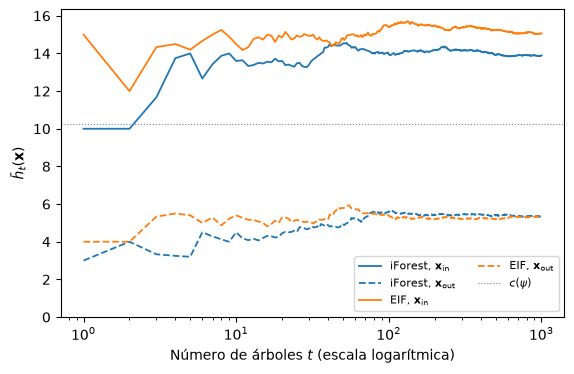

iForest: h media de x_in = 13.89, de x_out = 5.35 (1000 árboles)
EIF: h media de x_in = 15.06, de x_out = 5.32 (1000 árboles)


In [6]:
H_grande = bosques(X, semilla + 2, t=1000)
fig = V.dibujar_convergencia(H_grande, i_in, i_out, c(PSI))
V.guardar(fig, "E1_convergencia")
plt.show()
for metodo, H in H_grande.items():
    print(f"{metodo}: h media de x_in = {H[i_in].mean():.2f}, de x_out = {H[i_out].mean():.2f} (1000 árboles)")

### Puntuación de anomalía

La puntuación de anomalía es una función decreciente de $E(h(\mathbf{x}))$,
$$
s(\mathbf{x}, \psi) = 2^{-E(h(\mathbf{x}))/c(\psi)},
$$
que vale $1$ si $E(h(\mathbf{x})) \to 0$, $0.5$ si $E(h(\mathbf{x})) = c(\psi)$ y tiende a $0$ cuando
$E(h(\mathbf{x})) \to \psi - 1$. Como es decreciente, ordena las observaciones exactamente al revés que
$\bar h_t$, de modo que las medidas basadas en rangos son las mismas con una u otra. Dibujamos la curva para varios
valores de $\psi$ y situamos sobre ella las observaciones de la muestra, con el bosque de iForest de la réplica.

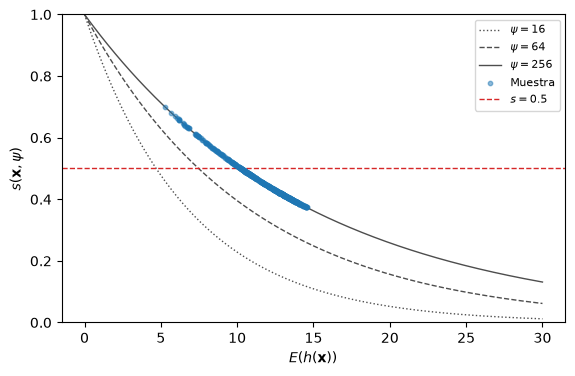

In [7]:
H = bosques(X, semilla)
h = {metodo: M.mean(axis=1) for metodo, M in H.items()}
fig = V.dibujar_puntuacion(h["iForest"], c)
V.guardar(fig, "E1_puntuacion")
plt.show()

### Profundidad de Tukey

Calculamos $HD(\mathbf{x}, P_n)$ de forma exacta con la biblioteca *data-depth*. Toma valores en
$\{1/n, 2/n, \dots\}$ (todas las observaciones de la muestra tienen profundidad al menos $1/n$), de modo que hay
muchos empates. Calculamos también la profundidad poblacional $HD(\mathbf{x}, P) = \Phi(-d_M(\mathbf{x}))$, con la
que se obtiene el techo.

In [8]:
hd = hd_muestral(X)
hd_P = esc.hd_P(X)
print(f"HD(x, P_n): mínimo {hd.min():.3f}, máximo {hd.max():.3f}, {len(np.unique(hd))} valores distintos")
print(f"HD(x_in, P_n) = {hd[i_in]:.3f},  HD(x_out, P_n) = {hd[i_out]:.3f}")

HD(x, P_n): mínimo 0.002, máximo 0.458, 174 valores distintos
HD(x_in, P_n) = 0.424,  HD(x_out, P_n) = 0.002


### Comparación con la profundidad de Tukey: dos escalas

La figura siguiente compara $\bar h_t$ con $HD(\cdot, P_n)$ en dos escalas, que responden a preguntas distintas.

- **Fila superior, rangos.** Cada observación se representa por su rango según cada medida, dividido entre $n$
  para llevarlo a $[0, 1]$. Es la escala en la que trabajan $\tau_b$ y $\rho_S$: si las dos medidas ordenasen igual,
  todos los puntos estarían sobre la diagonal. Los rangos reparten las observaciones de forma uniforme y permiten ver
  en qué zona (centro o periferia) se separan los dos órdenes, pero ocultan la forma de la relación.
- **Fila inferior, valores con $HD$ en escala logarítmica.** Se representa el valor de $\bar h_t$ frente a $HD$,
  con el eje horizontal en escala logarítmica. $HD(\cdot, P_n)$ toma los valores $1/n, 2/n, \dots$, que en escala
  lineal se amontonan cerca de $0$ precisamente donde están las observaciones periféricas; la escala logarítmica las
  separa. En esta escala la relación es aproximadamente una recta, $\bar h_t \approx a + b \log HD$, que se ajusta
  por mínimos cuadrados; $r_{\log}$ mide la calidad de ese ajuste. Las bandas verticales de la izquierda son los
  valores $HD = 1/n, 2/n, \dots$ compartidos por varias observaciones.

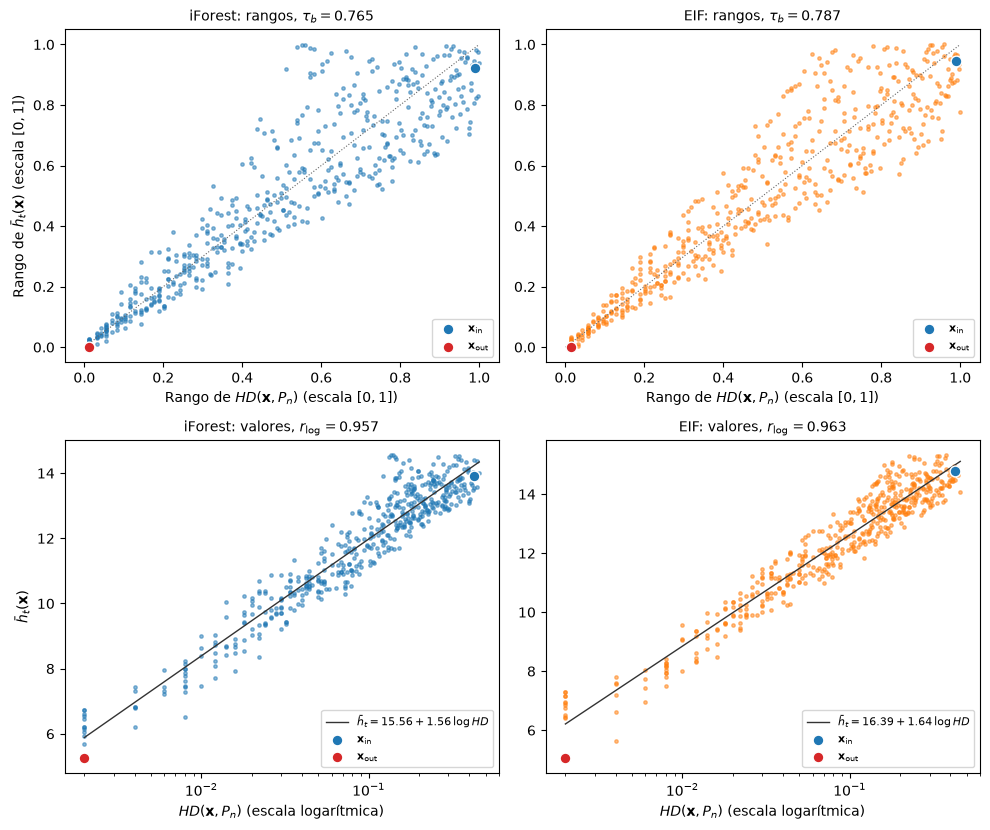

In [9]:
destacados = [(i_in, "tab:blue", r"$\mathbf{x}_{\mathrm{in}}$"), (i_out, "tab:red", r"$\mathbf{x}_{\mathrm{out}}$")]
fig = V.dibujar_h_frente_hd(h, hd, destacados)
V.guardar(fig, "E1_h_frente_hd")
plt.show()

Coloreamos la muestra según el rango de cada medida: los colores claros corresponden a las observaciones más
centrales.

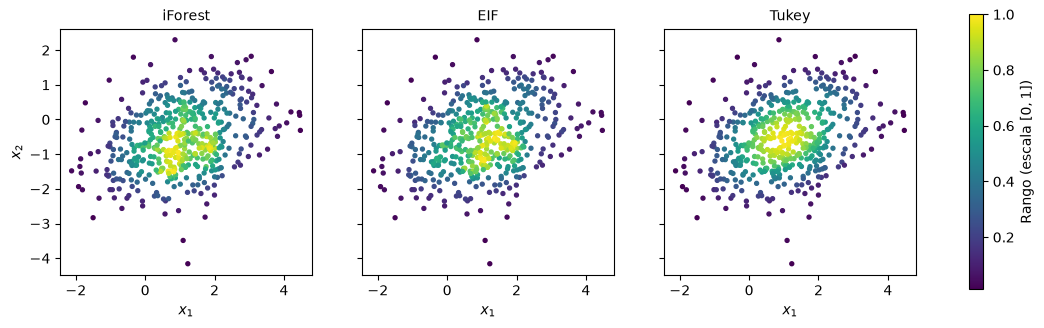

In [10]:
fig = V.dibujar_mapas(X, {"iForest": h["iForest"], "EIF": h["EIF"], "Tukey": hd})
V.guardar(fig, "E1_mapas")
plt.show()

Comparamos las observaciones menos centrales: el $5\,\%$ con menor $\bar h_t$ según cada método frente al
$5\,\%$ con menor profundidad de Tukey. Si hay empates en el punto de corte, se reparten al azar y se calcula el
solapamiento esperado.

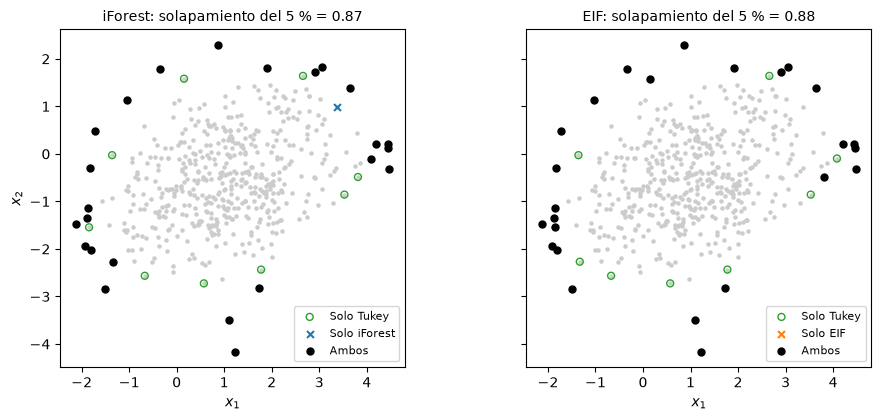

In [11]:
fig = V.dibujar_anomalias(X, h, hd)
V.guardar(fig, "E1_anomalias")
plt.show()

### Medidas de asociación

Para medir en qué grado $\bar h_t$ reproduce el orden de $HD(\cdot, P_n)$ usamos varias medidas, porque cada una
responde a una pregunta distinta. Sean $a_i = \bar h_t(\mathbf{x}_i)$ y $D_i = HD(\mathbf{x}_i, P_n)$.

- **$\tau_b$ de Kendall** (medida principal). Compara todos los pares de observaciones: un par es concordante si
  las dos medidas lo ordenan igual y discordante si lo ordenan al revés. Sin empates, $\tau_b = P(\text{concordante})
  - P(\text{discordante})$ para un par elegido al azar; la versión $b$ corrige los empates, que en
  $HD(\cdot, P_n)$ son muy frecuentes. Solo depende de los rangos, de modo que no cambia si se aplica a cualquiera de
  las dos variables una transformación creciente: mide si el orden coincide, que es justo la pregunta del trabajo.
- **$\rho_S$ de Spearman**. Es la correlación de Pearson entre los rangos. También mide asociación monótona, pero
  pesa más los pares con rangos muy alejados; se incluye como comprobación.
- **$r_{\log}$**: correlación de Pearson entre $\bar h_t$ y $\log HD(\cdot, P_n)$. La correlación de Pearson mide
  asociación **lineal** y depende de la escala de las variables, por lo que aplicada a $\bar h_t$ y $HD$ sin
  transformar infravalora una relación que es monótona pero curva. La gráfica en escala logarítmica muestra que la
  relación es aproximadamente lineal en $\log HD$, y $r_{\log}$ cuantifica la calidad de ese ajuste.
- **$\xi_n$ de Chatterjee** (2021): mide en qué grado $\bar h_t$ es una **función** de la profundidad, sea o no
  monótona. Vale $0$ (en el límite) si son independientes y $1$ si $\bar h_t$ es una función de $HD$. Comparado con
  $\tau_b$, permite distinguir dos fallos: si $\xi_n$ es alto y $\tau_b$ bajo, la longitud de ruta depende de la
  profundidad, pero no de forma creciente; si ambos son bajos, apenas depende de ella.
- **Solapamiento del $5\,\%$** y **$\tau_b$ en el centro** ($50\,\%$ más profundo) y **en la periferia** ($20\,\%$
  menos profundo): localizan dónde concuerdan y dónde no los dos órdenes.
- **Techo**: las mismas medidas entre la profundidad poblacional $HD(\cdot, P)$ y la muestral. Indica la
  concordancia que cabe esperar de un método ideal, que ordenase como la profundidad poblacional.

Las medidas de esta réplica coinciden con la fila $r = 0$ de `results/E1.csv`.

In [12]:
medidas(h, hd, hd_P)

,$\tau_b$,$\rho_S$,$r_{\log}$,$\xi_n$,Solapamiento 5 %,$\tau_b$ centro,$\tau_b$ periferia
iForest,0.765,0.917,0.957,0.642,0.873,0.369,0.720
EIF,0.787,0.932,0.963,0.672,0.884,0.419,0.801
Techo (HD poblacional),0.936,0.994,0.976,0.893,0.844,0.906,0.724


## Resultados sobre las 100 réplicas

Una réplica no basta para sacar conclusiones. La tabla resume las $100$ réplicas de E1 (media y, entre
paréntesis, desviación típica), y la siguiente compara los dos métodos réplica a réplica: diferencia media
(EIF menos iForest), número de réplicas en que el EIF obtiene un valor mayor y $p$-valor de la prueba de rangos con
signo de Wilcoxon.

In [13]:
E1 = pd.read_csv("../results/E1.csv")
V.tabla_resumen(E1)

R       $\tau_b$       $\rho_S$     $r_{\log}$        $\xi_n$ Solapamiento 5 % $\tau_b$ centro $\tau_b$ periferia
escenario método                                                                                                                      
E1        Techo    100  0.937 (0.014)  0.994 (0.003)  0.976 (0.011)  0.896 (0.022)    0.826 (0.056)   0.885 (0.035)      0.774 (0.052)
          iForest  100  0.819 (0.024)  0.951 (0.014)  0.969 (0.006)  0.731 (0.032)    0.835 (0.050)   0.538 (0.079)      0.761 (0.036)
          EIF      100  0.812 (0.028)  0.947 (0.016)  0.966 (0.006)  0.722 (0.035)    0.839 (0.054)   0.516 (0.093)      0.758 (0.035)

In [14]:
V.comparacion_pareada(E1, medidas=("tau_b", "r_log", "xi", "sol05"))

diferencia media réplicas a favor del EIF  p de Wilcoxon
escenario medida                                                                    
E1        $\tau_b$                    -0.007                 39 / 100      7.706e-03
          $r_{\log}$                  -0.003                 31 / 100      2.816e-05
          $\xi_n$                     -0.009                 43 / 100      1.624e-02
          Solapamiento 5 %             0.003                 43 / 100      4.600e-01

## Observaciones

- **Los dos órdenes se parecen, sobre todo en la periferia.** Sobre las 100 réplicas, la $\tau_b$ es de $0.819$
  (iForest) y $0.812$ (EIF), frente a un techo de $0.937$: aproximadamente el $91\,\%$ de los pares de observaciones
  están ordenados igual por la longitud de ruta media y por la profundidad de Tukey. En la periferia ($20\,\%$ menos
  profundo) los dos métodos están cerca del techo ($0.76$ frente a $0.77$), y el solapamiento del $5\,\%$
  ($0.84$) llega a superarlo ligeramente, porque el techo no es una cota superior para un método construido sobre la
  propia muestra. En el centro ($50\,\%$ más profundo) la $\tau_b$ baja a $0.52$–$0.54$, frente a $0.89$.
- **La relación es aproximadamente lineal en $\log HD$.** En la escala logarítmica, la nube de puntos sigue una
  recta, $\bar h_t \approx a + b \log HD$ con $b \approx 1.6$ en la primera réplica, y sobre las 100 réplicas
  $r_{\log} = 0.969$ y $0.966$, muy cerca del techo ($0.976$) y con desviaciones típicas de solo $0.006$. La forma de
  la relación es, por tanto, muy estable; el desacuerdo en los rangos procede del centro, donde muchas observaciones
  tienen profundidades y longitudes de ruta parecidas y el ruido altera su orden.
- **$\xi_n$ confirma la dependencia.** El coeficiente de Chatterjee, de $0.73$ y $0.72$ frente a $0.90$, indica que la
  longitud de ruta media está en gran medida determinada por la profundidad. Es menor que $\tau_b$, como ocurre siempre
  que la relación es creciente pero con ruido.
- **Con correlación baja, iForest y el EIF son prácticamente equivalentes.** El EIF es ligeramente peor en $\tau_b$,
  $r_{\log}$ y $\xi_n$ (diferencias de $0.003$ a $0.009$, significativas con la prueba de Wilcoxon), y no hay
  diferencias en el solapamiento del $5\,\%$ ($p = 0.46$). Son diferencias muy pequeñas frente a la distancia de
  ambos métodos al techo.